### CURRENT DIRECTORY

In [2]:
pwd

'C:\\Users\\Baron\\Desktop\\EE_258_Repo\\EE_258\\ML_PATH_EE258\\EE258_env\\projects'

In [3]:
import tensorflow as tf
print(tf.__version__)


2.18.0


### Pathing
    a. Baron's Pathing: 
        Main Location:'C:\\Users\\Baron\\Desktop\\EE_258_Repo\\EE_258\\ML_PATH_EE258\\EE258_env\\projects'
        Dataset: C:\Users\Baron\Documents\Grad_School\EE_258\project
        
    b. Hunter's Pathing:
        Main Location: '/Users/hunterakers/MachineLearning/my_env'
        Dataset: /Users/hunterakers/MachineLearning/my_env/DATASETS

### EE 258 Project Code

Table of Contents
    
    Part a) Preliminary Setup
    Part b) Dataset Description
    Part c) Dataset Visualization
    Part d) Pre Processing
    Part e) BASELINE MODEL
    Part f) MODELS UTILIZED: To be finished
    Part g) MODEL IMPROVEMENTS: To be finished
    Part h) PERFORMANCE & CONCLUSIONS: To be finished
    Part e) To be finished

### Part a) Preliminary Setup
    1. Import Necessary Libraries
    2. Import the Dataset

In [7]:
#1. Import Necessary Liobraries
import pandas as pd
import numpy as np
from PIL import Image
from tqdm import tqdm
import os

%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Input, AveragePooling2D, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l1


from keras.optimizers import Adam
from sklearn.model_selection import learning_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.utils import shuffle
from scikeras.wrappers import KerasClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from tensorflow.keras.losses import SparseCategoricalCrossentropy

import seaborn as sns

In [8]:
#2. Import the Dataset
##  Baron's Path
dataset_loc = r"C:\Users\Baron\Documents\Grad_School\EE_258\project\CUB_200_2011"

## Hunter's Path (Uncomment as needed)
#dataset_loc = r"/Users/hunterakers/MachineLearning/my_env/DATASETS/CUB_200_2011"


# Load key files
images_df = pd.read_csv(f"{dataset_loc}/images.txt", sep=" ", names=["image_id", "filepath"])
labels_df = pd.read_csv(f"{dataset_loc}/image_class_labels.txt", sep=" ", names=["image_id", "class_id"])
classes_df = pd.read_csv(f"{dataset_loc}/classes.txt", sep=" ", names=["class_id", "class_name"])
split_df = pd.read_csv(f"{dataset_loc}/train_test_split.txt", sep=" ", names=["image_id", "is_train"])  


# Merge into a single DataFrame
birds_df = images_df.merge(labels_df, on="image_id")
birds_df = birds_df.merge(split_df, on="image_id")
birds_df = birds_df.merge(classes_df, on="class_id")

# Add full image path
birds_df["images_filepath"] = dataset_loc + "/images/" + birds_df["filepath"]


### Part B) Dataset Description

    1. General Info
    2. Describing the Dataset
    3. Head of the Dataset
    4. Describing the characteristicts of the images
    4. Creating General Dataframes (For later use)
    

In [10]:
# 1. General Info
birds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11788 entries, 0 to 11787
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   image_id         11788 non-null  int64 
 1   filepath         11788 non-null  object
 2   class_id         11788 non-null  int64 
 3   is_train         11788 non-null  int64 
 4   class_name       11788 non-null  object
 5   images_filepath  11788 non-null  object
dtypes: int64(3), object(3)
memory usage: 552.7+ KB


In [11]:
#2. Describing the dataset
birds_df.describe()

,image_id,class_id,is_train
count,11788.000000,11788.000000,11788.000000
mean,5894.500000,101.126315,0.508483
std,3403.046821,57.476826,0.499949
min,1.000000,1.000000,0.000000
25%,2947.750000,51.000000,0.000000
50%,5894.500000,101.000000,1.000000
75%,8841.250000,151.000000,1.000000
max,11788.000000,200.000000,1.000000


In [12]:
#3. Head of the Dataset (Used to see a quick glimpse of the dataset)
birds_df.head(120)

,image_id,filepath,class_id,is_train,class_name,images_filepath
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,001.Black_footed_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,001.Black_footed_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
...,...,...,...,...,...,...
115,116,002.Laysan_Albatross/Laysan_Albatross_0083_756...,2,1,002.Laysan_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
116,117,002.Laysan_Albatross/Laysan_Albatross_0094_101...,2,1,002.Laysan_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
117,118,002.Laysan_Albatross/Laysan_Albatross_0103_504...,2,0,002.Laysan_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...
118,119,002.Laysan_Albatross/Laysan_Albatross_0079_506...,2,0,002.Laysan_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...


In [13]:
# Get the first 5 unique folder names from birds_df
first_five_folders = birds_df['filepath'].apply(lambda x: x.split('/')[0]).unique()[:5]

# Loop through the folders and count images
for folder in first_five_folders:
    folder_path = os.path.join(dataset_loc, 'images', folder)
    image_count = len([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])
    print(f"The folder '{folder}' contains {image_count} images.")

The folder '001.Black_footed_Albatross' contains 60 images.
The folder '002.Laysan_Albatross' contains 60 images.
The folder '003.Sooty_Albatross' contains 58 images.
The folder '004.Groove_billed_Ani' contains 60 images.
The folder '005.Crested_Auklet' contains 44 images.


In [14]:
for i in range(5):
    image_path = birds_df['images_filepath'].iloc[i]
    if os.path.exists(image_path):
        with Image.open(image_path) as img:
            print(img.size)  # Only outputs (width, height)
            

(500, 335)
(500, 336)
(500, 347)
(415, 500)
(331, 380)


### Part C) Dataset Visualization

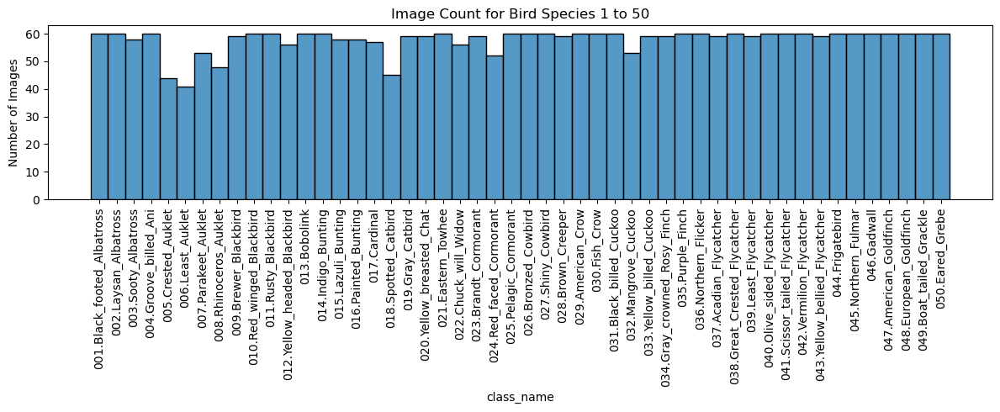

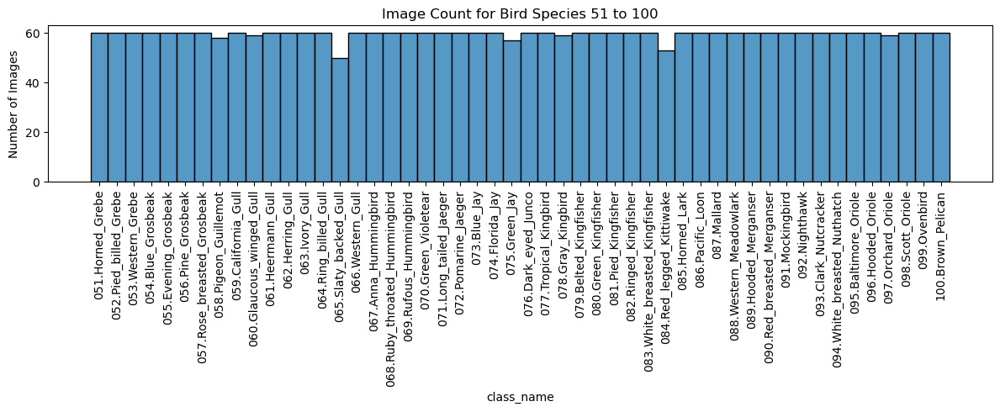

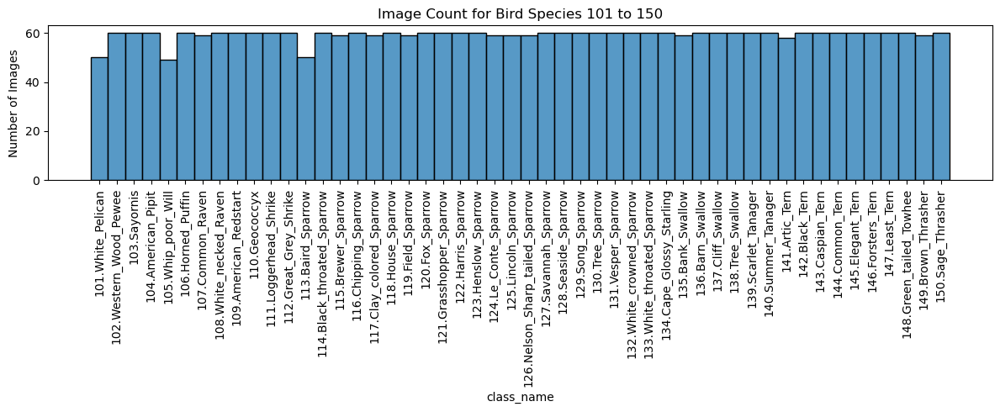

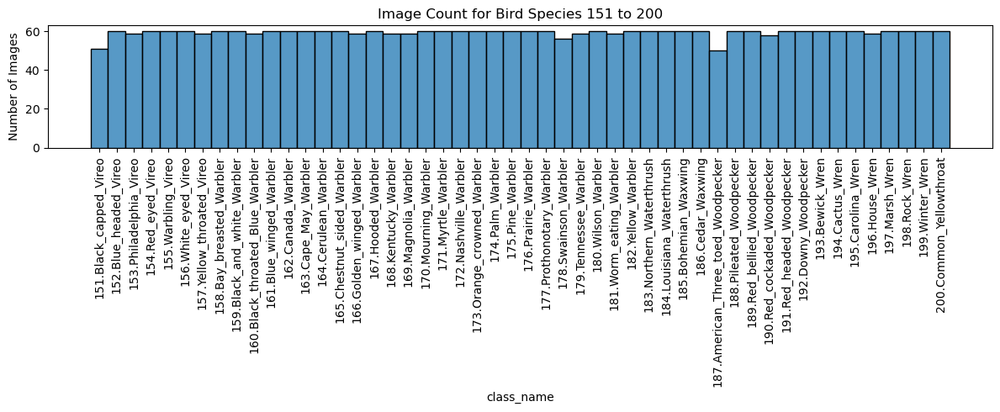

In [16]:
# Get sorted list of unique bird species
unique_classes = birds_df['class_name'].unique()
num_classes = len(unique_classes)
step = 50

for i in range(0, num_classes, step):
    subset = unique_classes[i:i+step]
    plt.figure(figsize=(12, 5))
    sns.histplot(data=birds_df[birds_df['class_name'].isin(subset)],
                 x='class_name', bins=step, kde=False)
    plt.xticks(rotation=90)
    plt.title(f"Image Count for Bird Species {i+1} to {i+step}")
    plt.ylabel("Number of Images")
    plt.tight_layout()
    plt.show()

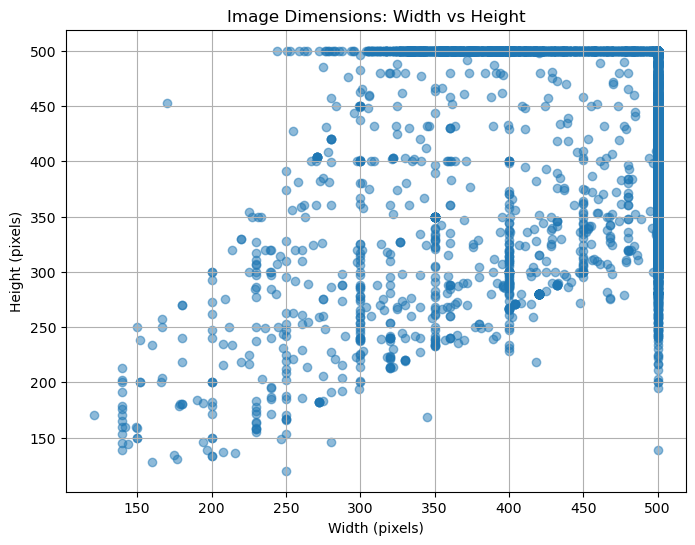

In [17]:
# Lists to hold width and height values
widths = []
heights = []

# Loop through all images
for path in birds_df["images_filepath"]:
    try:
        with Image.open(path) as img:
            width, height = img.size
            widths.append(width)
            heights.append(height)
    except Exception as e:
        print(f"Skipped {path}: {e}")

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(widths, heights, alpha=0.5)
plt.title("Image Dimensions: Width vs Height")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.grid(True)
plt.show()

Found 1004 image(s) with unusual dimensions.


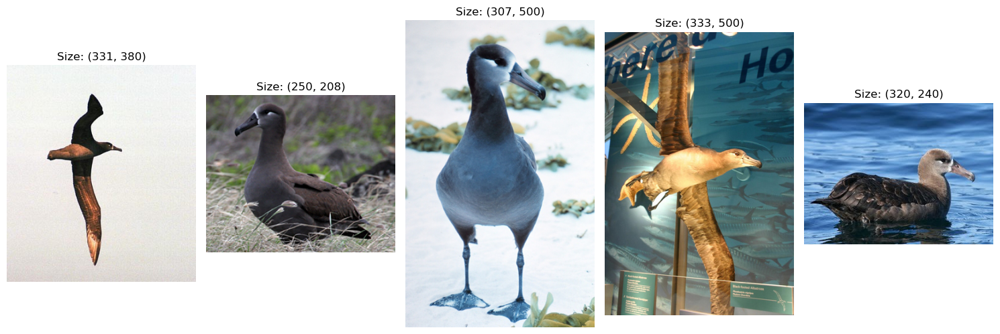

In [18]:
# Convert to NumPy arrays
widths_arr = np.array(widths)
heights_arr = np.array(heights)

# Calculate mean and standard deviation
w_mean, w_std = widths_arr.mean(), widths_arr.std()
h_mean, h_std = heights_arr.mean(), heights_arr.std()

# Identify images beyond 2 standard deviations in width or height
outlier_indices = [
    i for i, (w, h) in enumerate(zip(widths_arr, heights_arr))
    if abs(w - w_mean) > 2 * w_std or abs(h - h_mean) > 2 * h_std
]

print(f"Found {len(outlier_indices)} image(s) with unusual dimensions.")

# Display a few of the outlier images
from PIL import Image
fig, axes = plt.subplots(1, min(5, len(outlier_indices)), figsize=(15, 5))

for i, idx in enumerate(outlier_indices[:5]):
    path = birds_df.iloc[idx]['images_filepath']
    try:
        img = Image.open(path)
        axes[i].imshow(img)
        axes[i].set_title(f"Size: {img.size}")
        axes[i].axis('off')
    except Exception as e:
        print(f"Failed to open image {path}: {e}")

plt.tight_layout()
plt.show()

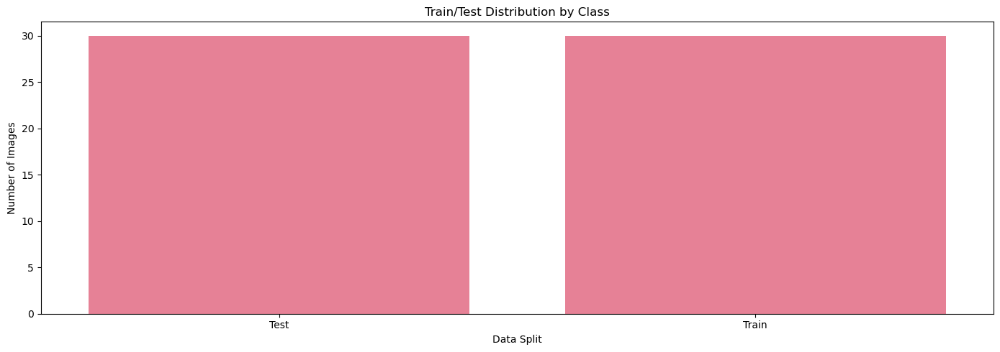

In [19]:
#Plots the data assigned to test and train
plt.figure(figsize=(14, 5))
sns.countplot(data=birds_df, x='is_train', hue='class_name', dodge=False)
plt.xticks([0, 1], ['Test', 'Train'])
plt.title("Train/Test Distribution by Class")
plt.xlabel("Data Split")
plt.ylabel("Number of Images")
plt.legend([],[], frameon=False)  # Hide legend for clarity
plt.tight_layout()
plt.show()

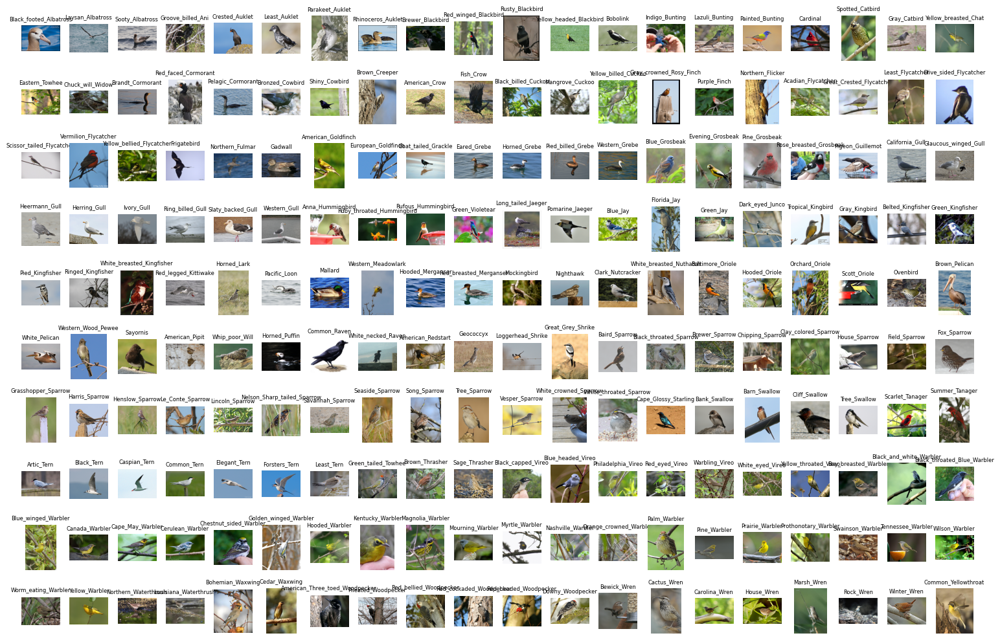

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Number of classes
NUM_CLASSES = birds_df['class_id'].nunique()

# Get one image per class
sample_df = birds_df.groupby('class_id').first().reset_index()

# Grid layout
cols = 20
rows = NUM_CLASSES // cols + int(NUM_CLASSES % cols > 0)
fig, axes = plt.subplots(rows, cols, figsize=(15, 10))
axes = axes.flatten()

for i, (_, row) in enumerate(sample_df.iterrows()):
    img = Image.open(row['images_filepath'])
    axes[i].imshow(img)
    axes[i].axis('off')
    # Shorten title by removing class ID prefix (e.g., "001.Red_winged_Blackbird" → "Red_winged_Blackbird")
    class_name = row['class_name'].split('.')[-1]
    axes[i].set_title(class_name, fontsize=6)

# Turn off unused axes
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


### Part D) Image Set Preprocessing

In [22]:
original_dir = os.path.join(dataset_loc, 'images')
processed_dir = os.path.join(dataset_loc, 'images_p')

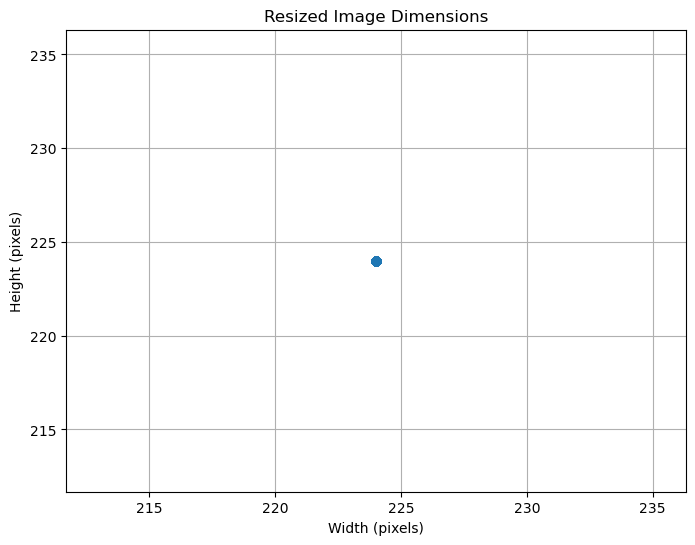

In [23]:
# Use the preprocessed directory
processed_dir = os.path.join(dataset_loc, 'images_p')

# Lists for widths and heights
new_widths = []
new_heights = []

# Walk and check dimensions
for root, dirs, files in os.walk(processed_dir):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            path = os.path.join(root, file)
            try:
                with Image.open(path) as img:
                    w, h = img.size
                    new_widths.append(w)
                    new_heights.append(h)
            except Exception as e:
                print(f"Error reading {path}: {e}")

# Plot new dimensions
plt.figure(figsize=(8, 6))
plt.scatter(new_widths, new_heights, alpha=0.5)
plt.title("Resized Image Dimensions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.grid(True)
plt.show()

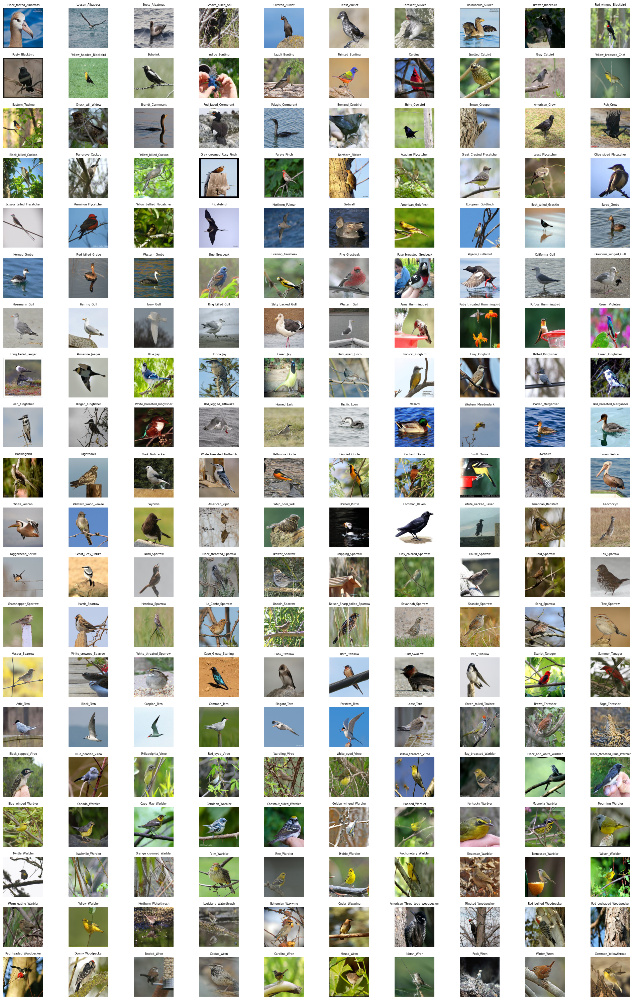

In [24]:
# One image per class
sample_df = birds_df.groupby('class_id').first().reset_index()

cols = 10
rows = len(sample_df) // cols + int(len(sample_df) % cols > 0)

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 1.5))
axes = axes.flatten()

for i, (_, row) in enumerate(sample_df.iterrows()):
    img_path = row['images_filepath'].replace('/images/', '/images_p/')
    try:
        img = Image.open(img_path)
        axes[i].imshow(img)
        class_name = row['class_name'].split('.')[-1]
        axes[i].set_title(class_name, fontsize=6)
        axes[i].axis('off')
    except Exception as e:
        print(f"Could not load image {img_path}: {e}")

# Turn off any unused axes
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

### PART E) Baseline Model
    The baseline model consists of a fully connected Neural Network

In [26]:
# Create a new column for resized image paths
birds_df["resized_path"] = birds_df["filepath"].apply(
    lambda x: os.path.join(dataset_loc, "images_p", x)
)

In [27]:
birds_df.head(1)

,image_id,filepath,class_id,is_train,class_name,images_filepath,resized_path
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,001.Black_footed_Albatross,C:\Users\Baron\Documents\Grad_School\EE_258\pr...,C:\Users\Baron\Documents\Grad_School\EE_258\pr...


In [28]:
# Save dataframe to csv to be analyzed.
birds_df.to_csv(r"C:\Users\Baron\Documents\Grad_School\EE_258\project\birds_df.csv", index=True)

In [29]:
## This code is responsible for choosing only the only the odd index of my dataframe.
    #In theory, this will decrease the number of output classes from 200 -> 100.

ouput_class_size = 100


# Step 1: Get 100 random class IDs
selected_classes = np.random.choice(birds_df['class_id'].unique(), size=ouput_class_size, replace=False)

# Step 2: Filter the dataframe to only include those classes
birds_df_filtered = birds_df[birds_df['class_id'].isin(selected_classes)].reset_index(drop=True)

# Step 3: Create a mapping from original class_id → 0 to 99
selected_class_ids = sorted(birds_df_filtered['class_id'].unique())
class_id_map = {orig_id: new_id for new_id, orig_id in enumerate(selected_class_ids)}

# Step 4: Apply the mapping
birds_df_filtered['class_id'] = birds_df_filtered['class_id'].map(class_id_map)

# Step 5: Stratified 80/20 train-test split with is_train label
train_parts = []
test_parts = []

for class_id, group in birds_df_filtered.groupby('class_id'):
    train_group, test_group = train_test_split(group, test_size=0.2, random_state=42, shuffle=True)
    train_group['is_train'] = 1
    test_group['is_train'] = 0
    train_parts.append(train_group)
    test_parts.append(test_group)

birds_df_filtered = pd.concat(train_parts + test_parts).reset_index(drop=True)

# Step 6: Summary printout
print(f"Filtered dataframe shape: {birds_df_filtered.shape}")
print(f"Number of unique classes: {birds_df_filtered['class_id'].nunique()}")
print(f"Class ID range: {birds_df_filtered['class_id'].min()} to {birds_df_filtered['class_id'].max()}")
print(birds_df_filtered['is_train'].value_counts())


Filtered dataframe shape: (5893, 7)
Number of unique classes: 100
Class ID range: 0 to 99
is_train
1    4707
0    1186
Name: count, dtype: int64


In [30]:
# Temporarily change pandas display settings
import pandas as pd
# Step 1: Create a small DataFrame from selected_classes
selected_classes_df = pd.DataFrame({'class_id': selected_classes})

# Step 2: Merge with the class name table
selected_classes_named = selected_classes_df.merge(classes_df, on='class_id', how='left')

with pd.option_context('display.max_rows', None):
    print("Selected bird classes (original IDs and names):")
    print(selected_classes_named.sort_values(by='class_id').reset_index(drop=True))


Selected bird classes (original IDs and names):
    class_id                          class_name
0          1          001.Black_footed_Albatross
1          2                002.Laysan_Albatross
2          3                 003.Sooty_Albatross
3          4               004.Groove_billed_Ani
4         10            010.Red_winged_Blackbird
5         11                 011.Rusty_Blackbird
6         12         012.Yellow_headed_Blackbird
7         14                  014.Indigo_Bunting
8         17                        017.Cardinal
9         18                 018.Spotted_Catbird
10        19                    019.Gray_Catbird
11        21                  021.Eastern_Towhee
12        23                023.Brandt_Cormorant
13        24             024.Red_faced_Cormorant
14        26                 026.Bronzed_Cowbird
15        29                   029.American_Crow
16        31             031.Black_billed_Cuckoo
17        32                 032.Mangrove_Cuckoo
18        35         

In [31]:
input_shape = (112, 112, 3)  # Width x Height x Channels
num_classes = ouput_class_size

# Define your FCNN model factory
def build_model():
    model = Sequential([
        Input(shape=(112, 112, 3)),
        AveragePooling2D(pool_size=(4, 4)),
        Flatten(),
        Dense(1024, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(512, activation='relu'),
        Dropout(0.4),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [32]:
# Build a fresh model each time
model_dense = build_model()

In [33]:
# View model summary
model_dense.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ average_pooling2d (AveragePooling2D) │ (None, 28, 28, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2352)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1024)                │       2,409,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1024)                │           4,096 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 100)                 │          25,700 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,095,396 (11.81 MB)

 Trainable params: 3,093,348 (11.80 MB)

 Non-trainable params: 2,048 (8.00 KB)

In [34]:
# Step 1: Split dataframes fro training and test and validation
train_birds_df = birds_df_filtered[birds_df_filtered["is_train"] == 1].copy()
test_birds_df = birds_df_filtered[birds_df_filtered["is_train"] == 0].copy()

val_df, final_test_df = train_test_split(
    test_birds_df,
    test_size=0.5,
    stratify=test_birds_df['class_id'],
    random_state=42
)

In [35]:
def load_images(df, target_size=(112, 112)):
    images = []
    labels = []

    for _, row in tqdm(df.iterrows(), total=len(df)):
        try:
            img = Image.open(row['resized_path']).convert('RGB')
            img = img.resize(target_size)
            img_array = np.array(img, dtype=np.float32) / 255.0
            images.append(img_array)
            labels.append(row['class_id'])
        except Exception as e:
            print(f"Failed to load {row['resized_path']}: {e}")
   
    return np.array(images, dtype=np.float32), np.array(labels)

In [36]:
#Uncomment for the final version
#Load the images
X_train, y_train = load_images(train_birds_df)
X_val, y_val = load_images(val_df)
x_test, y_test = load_images(final_test_df)


100%|███████████████████████████████████████████████████████████████████████████████| 593/593 [00:00<00:00, 719.48it/s]


In [37]:
print("First image pixel sample:", X_train[0, 0, 0])  # Should be ~0.0–1.0


First image pixel sample: [0.16862746 0.2784314  0.3647059 ]


In [38]:
# Preview the first image and label
print("Image shape:", X_train[0].shape)
print("Pixel values:\n", X_train[0])
print("Min pixel:", X_train[0].min())
print("Max pixel:", X_train[0].max())
print("Label:", y_train[0])

Image shape: (112, 112, 3)
Pixel values:
 [[[0.16862746 0.2784314  0.3647059 ]
  [0.1764706  0.28627452 0.37254903]
  [0.1764706  0.28627452 0.37254903]
  ...
  [0.18039216 0.32156864 0.45490196]
  [0.17254902 0.3137255  0.44705883]
  [0.17254902 0.3137255  0.44705883]]

 [[0.13333334 0.2509804  0.34509805]
  [0.14117648 0.25882354 0.3529412 ]
  [0.14901961 0.26666668 0.35686275]
  ...
  [0.17254902 0.3137255  0.44705883]
  [0.15686275 0.29803923 0.43137255]
  [0.15294118 0.29411766 0.42745098]]

 [[0.11372549 0.23137255 0.32941177]
  [0.12156863 0.24313726 0.3372549 ]
  [0.12941177 0.2509804  0.34509805]
  ...
  [0.16078432 0.3019608  0.43529412]
  [0.14509805 0.28627452 0.41960785]
  [0.14117648 0.28235295 0.41568628]]

 ...

 [[0.10980392 0.21960784 0.3019608 ]
  [0.13333334 0.24313726 0.33333334]
  [0.1254902  0.23137255 0.32941177]
  ...
  [0.2        0.3372549  0.47058824]
  [0.18039216 0.32156864 0.45490196]
  [0.17254902 0.3137255  0.45490196]]

 [[0.10980392 0.22745098 0.25882

In [39]:
from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',      # You can also use 'val_accuracy'
    patience=10,              # Stop if no improvement for 3 epochs
    restore_best_weights=True  # Roll back to the best weights
)

In [40]:
# Check for overlap
overlap = set(train_birds_df['image_id']) & set(test_birds_df['image_id'])
print(f"Number of overlapping images: {len(overlap)}")


Number of overlapping images: 0


In [41]:
## Run model fit
model_dense.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,                     # Can be high; early stopping will interrupt it
    callbacks=[early_stop]
)


Epoch 1/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.0145 - loss: 5.0362 - val_accuracy: 0.0118 - val_loss: 4.5738
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0192 - loss: 4.6714 - val_accuracy: 0.0202 - val_loss: 4.5555
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0210 - loss: 4.6116 - val_accuracy: 0.0135 - val_loss: 4.5245
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0276 - loss: 4.5451 - val_accuracy: 0.0337 - val_loss: 4.5319
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0306 - loss: 4.4996 - val_accuracy: 0.0185 - val_loss: 4.4975
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0410 - loss: 4.4580 - val_accuracy: 0.0236 - val_loss: 4.4757
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0438 - loss: 4.4266 - val_accuracy: 0.0320 - val_loss: 4.4477
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0435 - loss: 4.3833 - val_accu

In [42]:
test_loss, test_accuracy = model_dense.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0674 - loss: 4.0425 

Test Loss: 4.0537
Test Accuracy: 0.0793


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


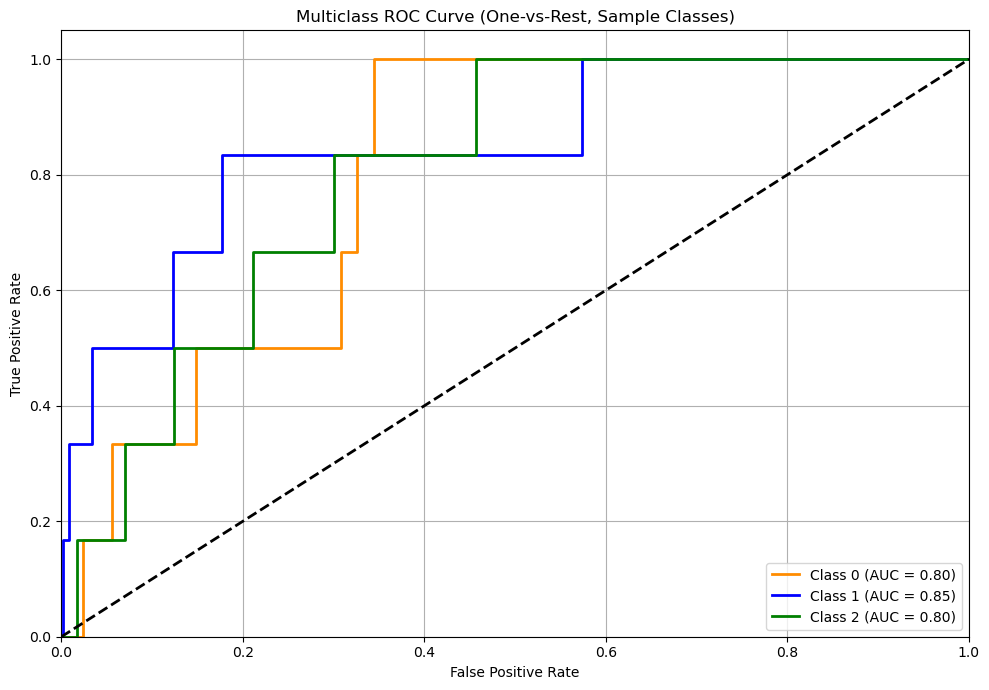

In [43]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
# Step 1: Predict class probabilities
y_score = model_dense.predict(x_test)  # Shape: (num_samples, num_classes)

# Step 2: Convert y_val to one-hot
y_val_bin = label_binarize(y_test, classes=np.arange(num_classes))  # Shape: (num_samples, num_classes)

# Step 3: Compute ROC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC for a few selected classes (e.g., 0, 1, 2)
plt.figure(figsize=(10, 7))
colors = ['darkorange', 'blue', 'green']
for i, color in zip([0, 1, 2], colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve (One-vs-Rest, Sample Classes)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


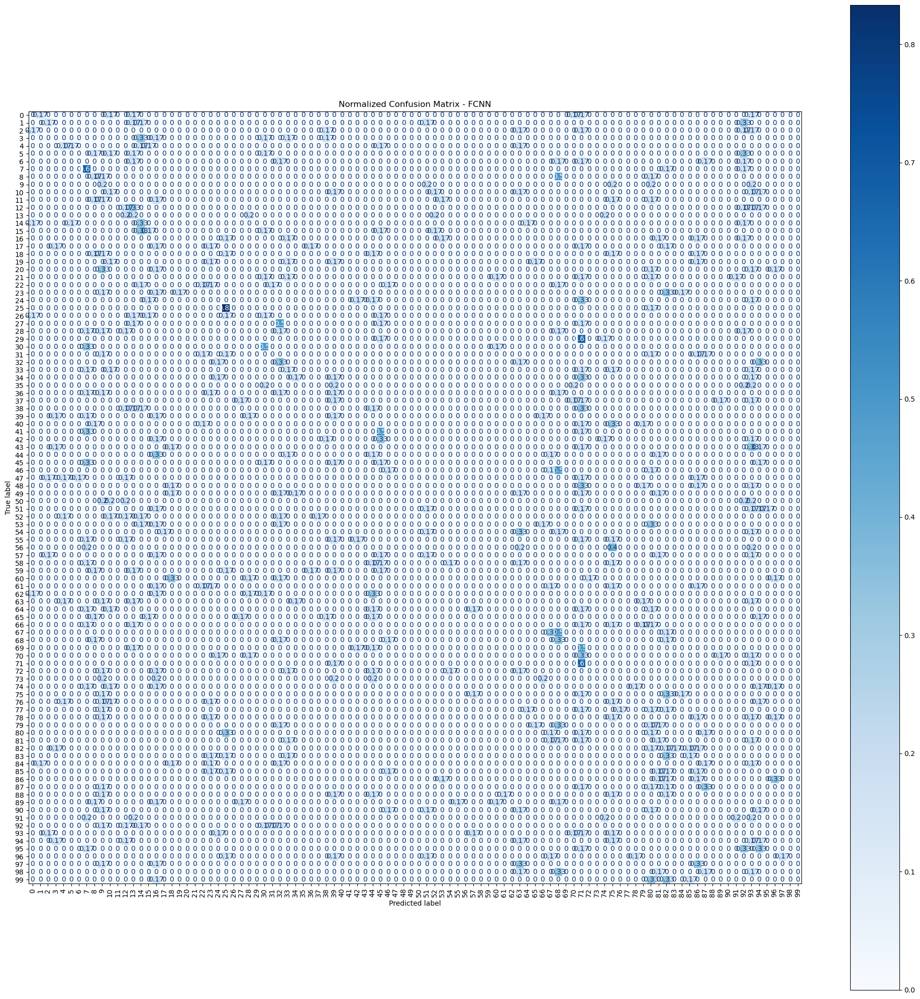

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Step 1: Get predictions from your model
# Get predictions
y_pred_probs = model_dense.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Normalize confusion matrix (rows sum to 1)
cm = confusion_matrix(y_test, y_pred, normalize='true')

# Plot it larger
fig, ax = plt.subplots(figsize=(20, 20))  # Bigger figure
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues', ax=ax, colorbar=True, xticks_rotation=90)
plt.title("Normalized Confusion Matrix - FCNN")
plt.tight_layout()
plt.show()

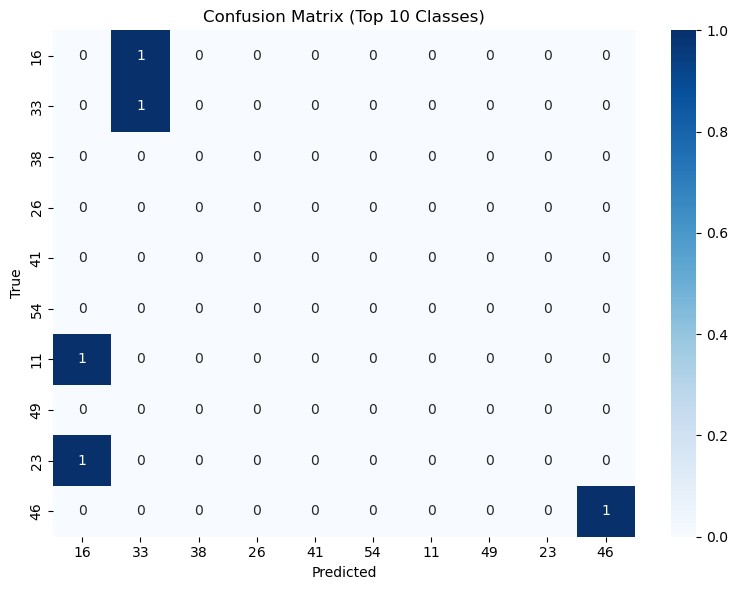

In [45]:
# Top N most common true classes
from collections import Counter 
top_classes = [cls for cls, _ in Counter(y_test).most_common(10)]

# Filter confusion matrix to top classes only
filtered_cm = confusion_matrix(y_test, y_pred)
filtered_cm = filtered_cm[np.ix_(top_classes, top_classes)]

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(filtered_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=top_classes, yticklabels=top_classes)
plt.title("Confusion Matrix (Top 10 Classes)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

### Part F) Models Utilized
    Futher models more complex than Fully Connected Neural Network were utilized

In [47]:
### Raw CNN Attempt

ouput_class_size = 100
input_shape = (224, 224, 3)  # Weight x Height x Channels
num_classes = ouput_class_size

# Best Test Accuracy / Poor Training Accuracy
def build_cnn_model_0(): 
    model_0 = Sequential([
        Input(shape=(112, 112, 3)),

        # Convolution Block 1
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        AveragePooling2D(pool_size=(4, 4)),
        BatchNormalization(),

        # Convolution Block 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        AveragePooling2D(pool_size=(2, 2)),
        BatchNormalization(),

        # Convolution Block 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        AveragePooling2D(pool_size=(2, 2)),
        BatchNormalization(),

        Flatten(),
        Dense(512, activation='relu'),   # ← 1st dense layer
        Dropout(0.5),
        Dense(256, activation='relu'),   # ← 2nd dense layer
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])

    model_0.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model_0

# Best Training Accuracy / Poor Test Accuracy
def build_cnn_model_1():
    model_1 = Sequential([
        Input(shape=(112, 112, 3)),

        # Convolution Block 1
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        AveragePooling2D(pool_size=(4, 4)),
        BatchNormalization(),

        # Convolution Block 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        AveragePooling2D(pool_size=(2, 2)),
        BatchNormalization(),

        # Convolution Block 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        AveragePooling2D(pool_size=(2, 2)),
        BatchNormalization(),

        Flatten(),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(num_classes, activation='softmax')
    ])

    model_1.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model_1

## Copy of model_cnn_0, regularization added.
def build_cnn_model_2():
    model_2 = Sequential([
        Input(shape=(112, 112, 3)),

        # Convolution Block 1
        Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=l1(1e-4)),
        MaxPooling2D(pool_size=(2, 2)),
        BatchNormalization(),

        # Convolution Block 2
        Conv2D(64, (3, 3), activation='relu', padding='same', kernel_regularizer=l1(1e-4)),
        MaxPooling2D(pool_size=(2, 2)),
        BatchNormalization(),

        # Convolution Block 3
        Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l1(1e-4)),
        MaxPooling2D(pool_size=(2, 2)),
        BatchNormalization(),

        Flatten(),
        Dense(512, activation='relu', kernel_regularizer=l1(1e-4)),
        Dropout(0.5),
        Dense(256, activation='relu', kernel_regularizer=l1(1e-4)),
        Dropout(0.3),

        Dense(num_classes, activation='softmax', kernel_regularizer=l1(1e-4))
    ])

    model_2.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model_2

def build_mlp_model():
    model = Sequential([
        Input(shape=(112, 112, 3)),     # Image input
        Flatten(),                      # Flatten to vector (224*224*3 = 150,528)

        Dense(1024, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(512, activation='relu'),
        Dropout(0.4),

        Dense(256, activation='relu'),
        Dropout(0.3),

        Dense(num_classes, activation='softmax')  # Output layer for classification
    ])

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


In [48]:
# Build a fresh model each time
model_cnn_0 = build_cnn_model_0()
model_cnn_1 = build_cnn_model_1()
model_cnn_2_l1reg = build_cnn_model_2()
model_mlp_0 = build_mlp_model()

In [49]:
# View model summary
model_cnn_0.summary()
model_cnn_1.summary()
model_cnn_2_l1reg.summary()
model_mlp_0.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 112, 112, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_1                  │ (None, 28, 28, 32)          │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 28, 28, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 28, 28, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_2                  │ (None, 14, 14, 64)          │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 14, 14, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 14, 14, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling2d_3                  │ (None, 7, 7, 128)           │               0 │
│ (AveragePooling2D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 7, 7, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 512)                 │       3,211,776 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 100)                 │          25,700 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,462,948 (13.21 MB)

 Trainable params: 3,462,500 (13.21 MB)

 Non-trainable params: 448 (1.75 KB)

...

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)                  │ (None, 37632)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 1024)                │      38,536,192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 1024)                │           4,096 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 100)                 │          25,700 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 39,222,116 (149.62 MB)

 Trainable params: 39,220,068 (149.61 MB)

 Non-trainable params: 2,048 (8.00 KB)

In [50]:
from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',      # You can also use 'val_accuracy'
    patience=10,              # Stop if no improvement for 3 epochs
    restore_best_weights=True  # Roll back to the best weights
)

In [51]:
## Run model fit
model_cnn_0.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,                     # Can be high; early stopping will interrupt it
    callbacks=[early_stop]
)


Epoch 1/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.0159 - loss: 5.2860 - val_accuracy: 0.0101 - val_loss: 4.6170
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 87ms/step - accuracy: 0.0359 - loss: 4.6155 - val_accuracy: 0.0152 - val_loss: 4.5990
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 86ms/step - accuracy: 0.0559 - loss: 4.3781 - val_accuracy: 0.0422 - val_loss: 4.4618
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 87ms/step - accuracy: 0.0816 - loss: 4.1913 - val_accuracy: 0.0658 - val_loss: 4.2655
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 87ms/step - accuracy: 0.1071 - loss: 4.0229 - val_accuracy: 0.0860 - val_loss: 4.1229
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.1267 - loss: 3.8681 - val_accuracy: 0.0860 - val_loss: 4.0011
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.1518 - loss: 3.6804 - val_accuracy: 0.1029 - val_loss: 3.9379
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 88ms/step - accuracy: 0.1745 - loss: 3.4778 - 

In [52]:
test_loss, test_accuracy = model_cnn_0.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1701 - loss: 3.5941

Test Loss: 3.5594
Test Accuracy: 0.1686


In [53]:
# Step 1: Predict class probabilities
y_pred_probs = model_cnn_0.predict(x_test)

# Step 2: Convert to predicted class labels
y_pred = np.argmax(y_pred_probs, axis=1)

# Step 3: Print classification report
print(classification_report(y_test, y_pred, digits=3))

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step 
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         6
           1      0.200     0.167     0.182         6
           2      0.000     0.000     0.000         6
           3      0.231     0.500     0.316         6
           4      0.000     0.000     0.000         6
           5      0.000     0.000     0.000         6
           6      1.000     0.500     0.667         6
           7      0.286     0.333     0.308         6
           8      0.333     0.167     0.222         6
           9      0.286     0.400     0.333         5
          10      0.000     0.000     0.000         6
          11      0.000     0.000     0.000         6
          12      0.167     0.333     0.222         6
          13      0.111     0.200     0.143         5
          14      0.400     0.333     0.364         6
          15      0.250     0.167     0.200         6
          16      0.100     0.167     0.

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


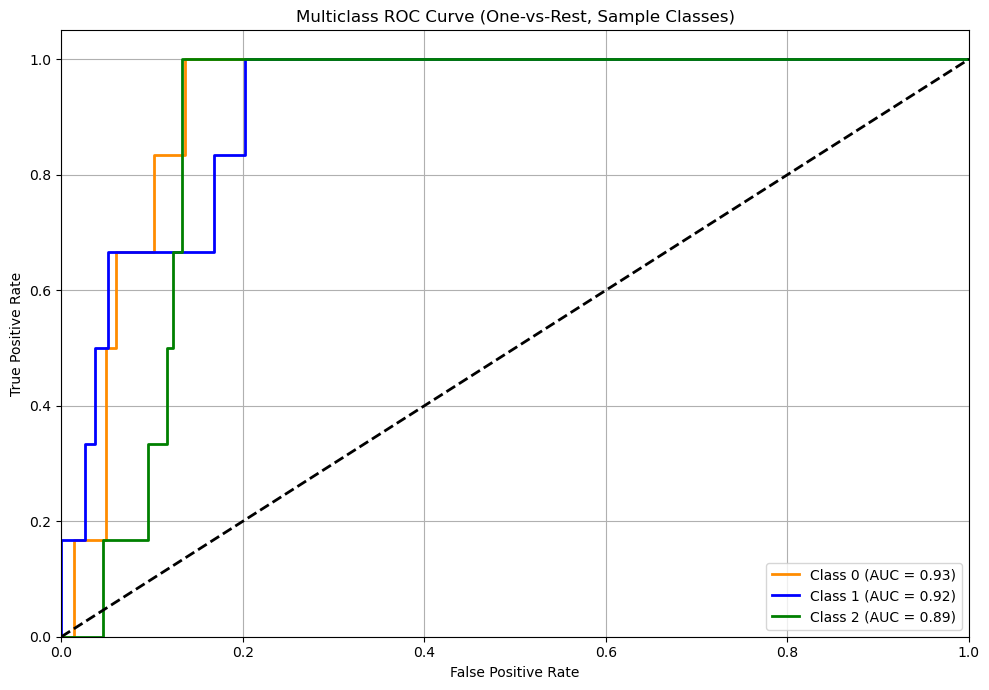

In [54]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
# Step 1: Predict class probabilities
y_score = model_cnn_0.predict(x_test)  # Shape: (num_samples, num_classes)

# Step 2: Convert y_val to one-hot
y_val_bin = label_binarize(y_test, classes=np.arange(num_classes))  # Shape: (num_samples, num_classes)

# Step 3: Compute ROC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC for a few selected classes (e.g., 0, 1, 2)
plt.figure(figsize=(10, 7))
colors = ['darkorange', 'blue', 'green']
for i, color in zip([0, 1, 2], colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve (One-vs-Rest, Sample Classes)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

### Models

In [56]:
## Run model fit
model_cnn_1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,                     # Can be high; early stopping will interrupt it
    callbacks=[early_stop]
)


Epoch 1/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.0142 - loss: 5.6332 - val_accuracy: 0.0118 - val_loss: 4.6537
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.0500 - loss: 4.7311 - val_accuracy: 0.0185 - val_loss: 4.6270
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.0826 - loss: 4.2863 - val_accuracy: 0.0573 - val_loss: 4.3620
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.1297 - loss: 3.8874 - val_accuracy: 0.0944 - val_loss: 4.0750
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.1802 - loss: 3.5646 - val_accuracy: 0.1180 - val_loss: 3.9082
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.2424 - loss: 3.1754 - val_accuracy: 0.1265 - val_loss: 3.8785
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.2831 - loss: 2.9519 - val_accuracy: 0.1332 - val_loss: 3.8154
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.3582 - loss: 2.6123 - 

In [57]:
test_loss, test_accuracy = model_cnn_1.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1516 - loss: 3.9064

Test Loss: 3.8529
Test Accuracy: 0.1417


In [58]:
# Step 1: Predict class probabilities
y_pred_probs = model_cnn_1.predict(x_test)

# Step 2: Convert to predicted class labels
y_pred = np.argmax(y_pred_probs, axis=1)

# Step 3: Print classification report
print(classification_report(y_test, y_pred, digits=3))

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step 
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         6
           1      0.333     0.333     0.333         6
           2      0.062     0.167     0.091         6
           3      0.000     0.000     0.000         6
           4      0.000     0.000     0.000         6
           5      0.000     0.000     0.000         6
           6      0.600     0.500     0.545         6
           7      0.429     0.500     0.462         6
           8      0.000     0.000     0.000         6
           9      0.250     0.200     0.222         5
          10      0.000     0.000     0.000         6
          11      0.200     0.167     0.182         6
          12      0.250     0.167     0.200         6
          13      0.000     0.000     0.000         5
          14      0.143     0.167     0.154         6
          15      0.077     0.167     0.105         6
          16      0.000     0.000     0.

C:\Users\Baron\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Baron\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Baron\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


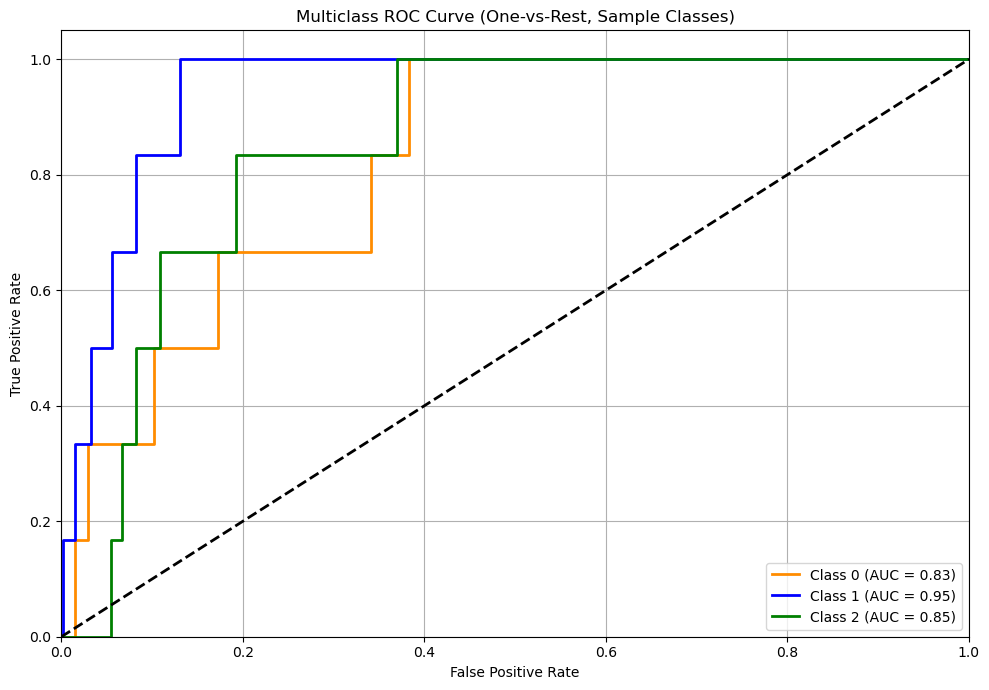

In [59]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
# Step 1: Predict class probabilities
y_score = model_cnn_1.predict(x_test)  # Shape: (num_samples, num_classes)

# Step 2: Convert y_val to one-hot
y_val_bin = label_binarize(y_test, classes=np.arange(num_classes))  # Shape: (num_samples, num_classes)

# Step 3: Compute ROC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC for a few selected classes (e.g., 0, 1, 2)
plt.figure(figsize=(10, 7))
colors = ['darkorange', 'blue', 'green']
for i, color in zip([0, 1, 2], colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve (One-vs-Rest, Sample Classes)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [60]:
### Running the MLP Model 
model_mlp_0.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,                     # Can be high; early stopping will interrupt it
    callbacks=[early_stop]
)

Epoch 1/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 37s 239ms/step - accuracy: 0.0130 - loss: 5.1007 - val_accuracy: 0.0185 - val_loss: 4.5950
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 35s 237ms/step - accuracy: 0.0163 - loss: 4.7306 - val_accuracy: 0.0152 - val_loss: 4.5646
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 35s 236ms/step - accuracy: 0.0162 - loss: 4.6500 - val_accuracy: 0.0219 - val_loss: 4.5665
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 35s 236ms/step - accuracy: 0.0227 - loss: 4.5775 - val_accuracy: 0.0219 - val_loss: 4.5395
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 36s 241ms/step - accuracy: 0.0251 - loss: 4.5470 - val_accuracy: 0.0202 - val_loss: 4.5311
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 35s 238ms/step - accuracy: 0.0341 - loss: 4.5355 - val_accuracy: 0.0320 - val_loss: 4.5148
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 36s 240ms/step - accuracy: 0.0279 - loss: 4.5032 - val_accuracy: 0.0253 - val_loss: 4.4991
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 35s 238ms/step - accuracy: 0.0308 - loss: 4

In [61]:
test_loss, test_accuracy = model_mlp_0.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0607 - loss: 4.0642

Test Loss: 4.0695
Test Accuracy: 0.0641


In [62]:
# Step 1: Predict class probabilities
y_pred_probs = model_mlp_0.predict(x_test)

# Step 2: Convert to predicted class labels
y_pred = np.argmax(y_pred_probs, axis=1)

# Step 3: Print classification report
print(classification_report(y_test, y_pred, digits=3))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         6
           1      0.333     0.167     0.222         6
           2      0.000     0.000     0.000         6
           3      0.000     0.000     0.000         6
           4      0.000     0.000     0.000         6
           5      0.000     0.000     0.000         6
           6      0.000     0.000     0.000         6
           7      0.190     0.667     0.296         6
           8      0.071     0.167     0.100         6
           9      0.000     0.000     0.000         5
          10      0.000     0.000     0.000         6
          11      0.000     0.000     0.000         6
          12      0.000     0.000     0.000         6
          13      0.000     0.000     0.000         5
          14      0.000     0.000     0.000         6
          15      0.000     0.000     0.000         6
          16      0.000     0.000     0.0

C:\Users\Baron\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Baron\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Baron\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


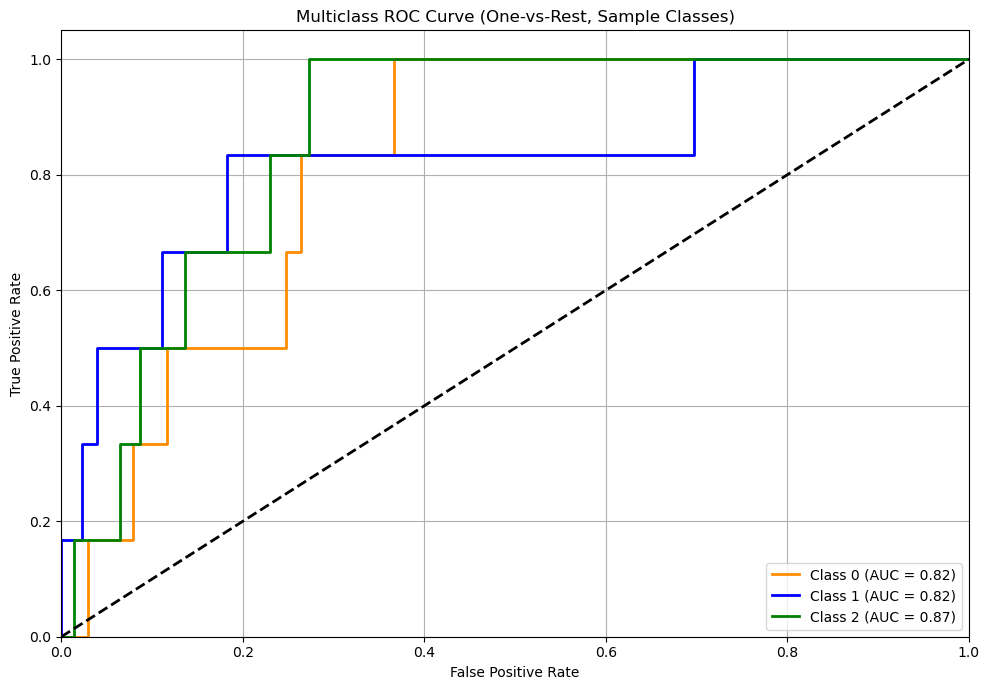

In [63]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
# Step 1: Predict class probabilities
y_score = model_mlp_0.predict(x_test)  # Shape: (num_samples, num_classes)

# Step 2: Convert y_val to one-hot
y_val_bin = label_binarize(y_test, classes=np.arange(num_classes))  # Shape: (num_samples, num_classes)

# Step 3: Compute ROC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC for a few selected classes (e.g., 0, 1, 2)
plt.figure(figsize=(10, 7))
colors = ['darkorange', 'blue', 'green']
for i, color in zip([0, 1, 2], colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve (One-vs-Rest, Sample Classes)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

### Part G) Model Improvements
    1. Data Augmentation
    2. Regularization
    3. Hyperparameter Selection

In [65]:
X_train_aug = X_train

In [66]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create the generator with augmentations
image_aug_gen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)


In [67]:
## Run model fit
model_cnn_0.fit(
    image_aug_gen.flow(X_train_aug, y_train, batch_size=32),
    validation_data=(X_val, y_val),
    epochs=50,                     # Can be high; early stopping will interrupt it
    callbacks=[early_stop]
)

C:\Users\Baron\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 20s 138ms/step - accuracy: 0.2083 - loss: 3.7288 - val_accuracy: 0.1922 - val_loss: 3.3769
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 20s 138ms/step - accuracy: 0.1877 - loss: 3.4793 - val_accuracy: 0.2024 - val_loss: 3.2784
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 20s 137ms/step - accuracy: 0.2064 - loss: 3.3430 - val_accuracy: 0.1788 - val_loss: 3.3444
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 21s 138ms/step - accuracy: 0.2295 - loss: 3.2313 - val_accuracy: 0.2344 - val_loss: 3.1876
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 20s 137ms/step - accuracy: 0.2402 - loss: 3.1094 - val_accuracy: 0.2125 - val_loss: 3.2185
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 21s 139ms/step - accuracy: 0.2468 - loss: 3.0773 - val_accuracy: 0.2428 - val_loss: 3.1055
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 20s 138ms/step - accuracy: 0.2643 - loss: 3.0396 - val_accuracy: 0.2293 - val_loss: 3.1318
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 21s 138ms/step - accuracy: 0.2494 - loss: 3

In [68]:
test_loss, test_accuracy = model_cnn_0.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2968 - loss: 2.8217

Test Loss: 2.8132
Test Accuracy: 0.2833


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


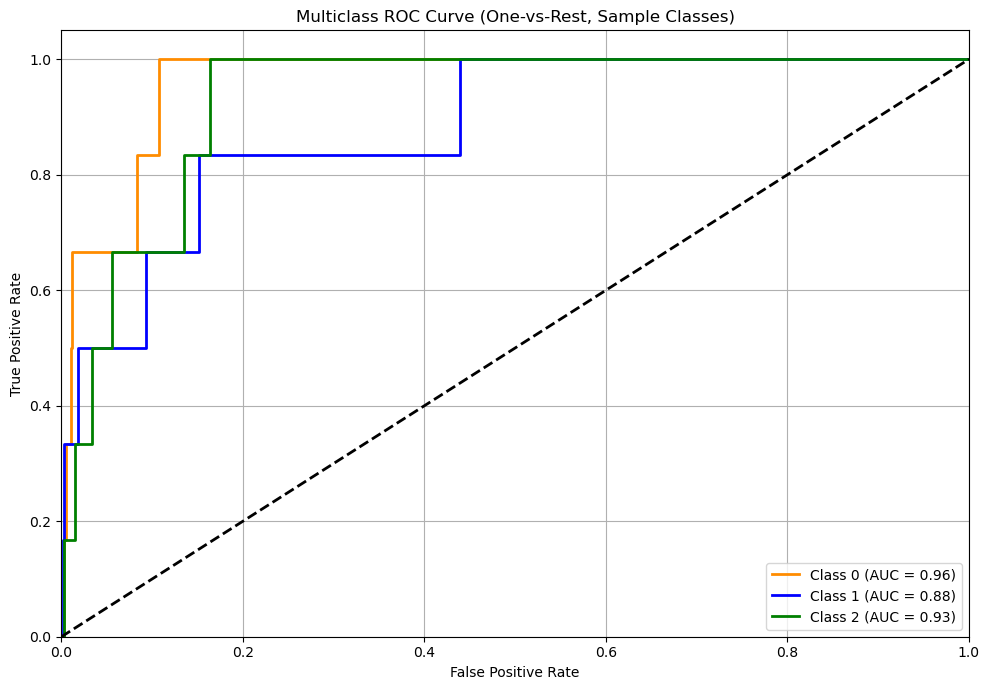

In [69]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
# Step 1: Predict class probabilities
y_score = model_cnn_0.predict(x_test)  # Shape: (num_samples, num_classes)

# Step 2: Convert y_val to one-hot
y_val_bin = label_binarize(y_test, classes=np.arange(num_classes))  # Shape: (num_samples, num_classes)

# Step 3: Compute ROC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC for a few selected classes (e.g., 0, 1, 2)
plt.figure(figsize=(10, 7))
colors = ['darkorange', 'blue', 'green']
for i, color in zip([0, 1, 2], colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve (One-vs-Rest, Sample Classes)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [70]:
## Run model fit
model_cnn_1.fit(
    image_aug_gen.flow(X_train_aug, y_train, batch_size=32),
    validation_data=(X_val, y_val),
    epochs=50,                     # Can be high; early stopping will interrupt it
    callbacks=[early_stop]
)

Epoch 1/50


C:\Users\Baron\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 128ms/step - accuracy: 0.1607 - loss: 3.8078 - val_accuracy: 0.1400 - val_loss: 3.7003
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - accuracy: 0.1713 - loss: 3.6147 - val_accuracy: 0.1467 - val_loss: 3.6313
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 128ms/step - accuracy: 0.1956 - loss: 3.5021 - val_accuracy: 0.1737 - val_loss: 3.5094
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 128ms/step - accuracy: 0.2082 - loss: 3.4255 - val_accuracy: 0.1804 - val_loss: 3.4353
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 128ms/step - accuracy: 0.2305 - loss: 3.2730 - val_accuracy: 0.1922 - val_loss: 3.3615
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - accuracy: 0.2224 - loss: 3.1993 - val_accuracy: 0.1990 - val_loss: 3.3917
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - accuracy: 0.2348 - loss: 3.1210 - val_accuracy: 0.1990 - val_loss: 3.3288
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - accuracy: 0.2445 - loss: 3.0991 - val

In [71]:
test_loss, test_accuracy = model_cnn_1.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2379 - loss: 2.9750

Test Loss: 2.9574
Test Accuracy: 0.2597


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


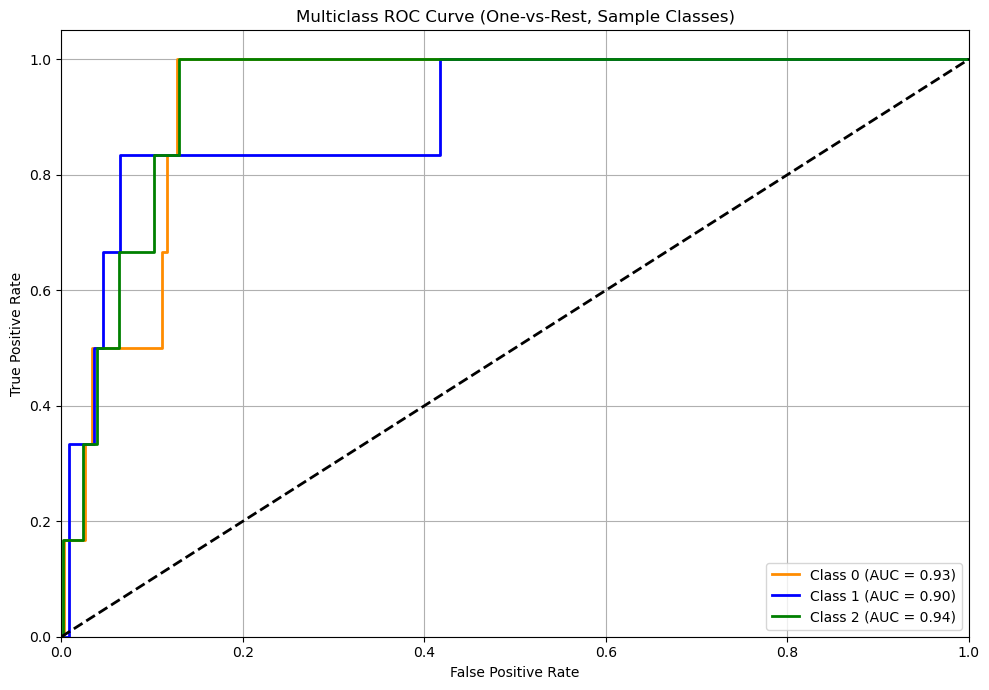

In [72]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
# Step 1: Predict class probabilities
y_score = model_cnn_1.predict(x_test)  # Shape: (num_samples, num_classes)

# Step 2: Convert y_val to one-hot
y_val_bin = label_binarize(y_test, classes=np.arange(num_classes))  # Shape: (num_samples, num_classes)

# Step 3: Compute ROC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC for a few selected classes (e.g., 0, 1, 2)
plt.figure(figsize=(10, 7))
colors = ['darkorange', 'blue', 'green']
for i, color in zip([0, 1, 2], colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve (One-vs-Rest, Sample Classes)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [155]:
## ## Copy of model_cnn_0, regularization added.
model_cnn_2_l1reg.fit(
    image_aug_gen.flow(X_train_aug , y_train, batch_size=32),
    validation_data=(X_val, y_val),
    epochs=200,                     # Can be high; early stopping will interrupt it
    callbacks=[early_stop]
)

Epoch 1/200


C:\Users\Baron\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


148/148 ━━━━━━━━━━━━━━━━━━━━ 41s 274ms/step - accuracy: 0.3082 - loss: 5.9103 - val_accuracy: 0.3019 - val_loss: 6.0162
Epoch 2/200
148/148 ━━━━━━━━━━━━━━━━━━━━ 42s 283ms/step - accuracy: 0.3098 - loss: 5.8425 - val_accuracy: 0.2951 - val_loss: 6.0180
Epoch 3/200
148/148 ━━━━━━━━━━━━━━━━━━━━ 40s 273ms/step - accuracy: 0.3145 - loss: 5.8869 - val_accuracy: 0.3305 - val_loss: 5.9273
Epoch 4/200
148/148 ━━━━━━━━━━━━━━━━━━━━ 41s 274ms/step - accuracy: 0.3326 - loss: 5.7524 - val_accuracy: 0.3069 - val_loss: 6.0062
Epoch 5/200
148/148 ━━━━━━━━━━━━━━━━━━━━ 41s 277ms/step - accuracy: 0.3475 - loss: 5.7535 - val_accuracy: 0.2901 - val_loss: 6.0504
Epoch 6/200
148/148 ━━━━━━━━━━━━━━━━━━━━ 41s 279ms/step - accuracy: 0.3240 - loss: 5.7848 - val_accuracy: 0.3272 - val_loss: 5.9282
Epoch 7/200
148/148 ━━━━━━━━━━━━━━━━━━━━ 42s 282ms/step - accuracy: 0.3312 - loss: 5.7592 - val_accuracy: 0.2884 - val_loss: 5.9888
Epoch 8/200
148/148 ━━━━━━━━━━━━━━━━━━━━ 41s 277ms/step - accuracy: 0.3562 - loss: 5.701

In [157]:
test_loss, test_accuracy = model_cnn_2_l1reg.evaluate(x_test, y_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3470 - loss: 5.9440

Test Loss: 5.9584
Test Accuracy: 0.3508


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


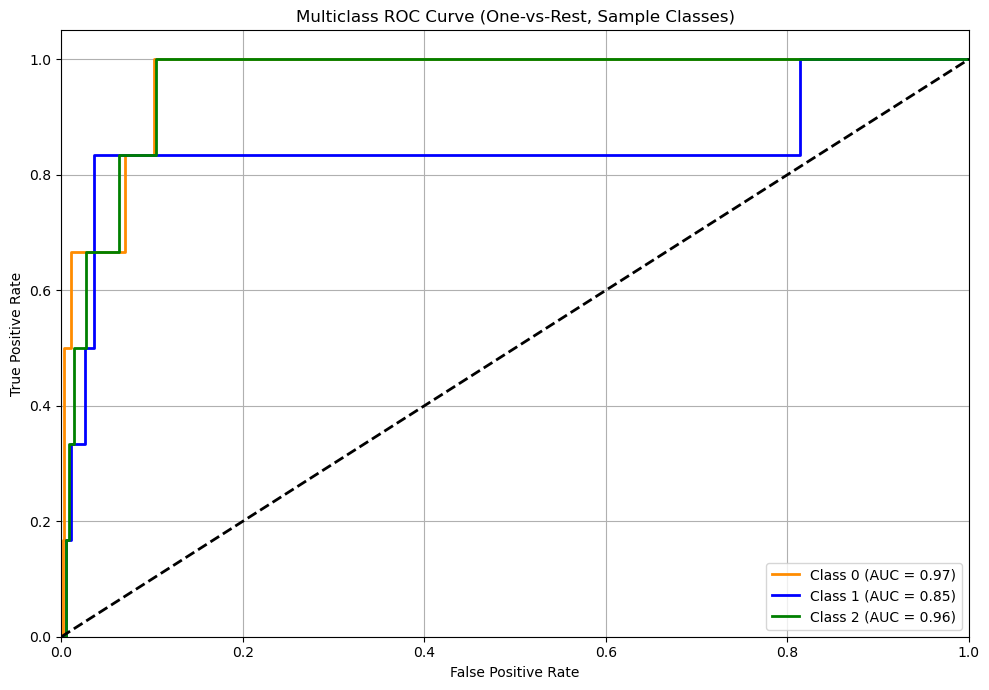

In [161]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
# Step 1: Predict class probabilities
y_score = model_cnn_2_l1reg.predict(x_test)  # Shape: (num_samples, num_classes)

# Step 2: Convert y_val to one-hot
y_val_bin = label_binarize(y_test, classes=np.arange(num_classes))  # Shape: (num_samples, num_classes)

# Step 3: Compute ROC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Step 4: Plot ROC for a few selected classes (e.g., 0, 1, 2)
plt.figure(figsize=(10, 7))
colors = ['darkorange', 'blue', 'green']
for i, color in zip([0, 1, 2], colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve (One-vs-Rest, Sample Classes)')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()